# Week 6 - Day 2

# Neural Networks with Keras: Multi-Class Image Classification

Yesterday we built our first Artificial Neural Network - a binary classifier that predicted `Loan_Approved` (0 or 1) from an applicant's form data.

Today we go a level deeper into how Keras training actually works internally, and we tackle a **multi-class** problem for the first time: recognising handwritten digits (0-9) from images.

This lesson directly sets up Week 7, where we'll build a **CNN** designed specifically for image data.

## Learning Objectives

By the end of this lesson, you will be able to:

- Explain the four stages of training a Neural Network: forward pass, loss calculation, backpropagation, and epochs.
- Use the Keras `Sequential` API to build a network for a **multi-class** classification problem.
- Explain the difference between binary and multi-class output layers (`sigmoid` vs `softmax`).
- Flatten image data into a format a Dense layer can use.
- Train an ANN on an image dataset and visualize accuracy/loss curves.
- Compare models with different numbers of hidden layers and explain the effect on performance.
- Use `Dropout` to reduce overfitting.
- Read a multi-class confusion matrix.

## Why This Lesson Matters

Yesterday's loan model only ever had to choose between **two** outcomes. But most real-world classification problems have more than two possible answers:

- A bank app reading a handwritten cheque amount: 10 possible digits, not 2.
- A customer support system routing a message to one of 8 departments.
- A produce-sorting app in a Lagos market recognising tomatoes, peppers, or onions.

Today's digit-recognition task is the classic "hello world" of image-based Neural Networks, precisely because it forces us to handle **more than two classes** for the first time.

## Recap: Week 6 Day 1

| Concept | Day 1 (Loan Approval) | Today (Digit Recognition) |
|---|---|---|
| Problem type | Binary classification | Multi-class classification |
| Input data | Tabular (spreadsheet rows) | Images (pixel grids) |
| Output layer | 1 neuron, `sigmoid` | 10 neurons, `softmax` |
| Loss function | `binary_crossentropy` | `sparse_categorical_crossentropy` |
| Dataset size | ~1,000 applicants | ~1,800 digit images |

Everything else - Dense layers, ReLU, the Sequential API, epochs, batch size - carries over unchanged. We are extending what we already know, not starting over.

# Part 1 - How Keras Training Actually Works

Yesterday we called `model.fit()` and it "just worked." Let's open up what happens inside every single epoch.

<svg viewBox="0 0 900 460" xmlns="http://www.w3.org/2000/svg">
  <rect width="900" height="460" fill="#f8f9fa"/>
  <text x="450" y="35" font-size="18" font-weight="bold" text-anchor="middle" fill="#1565c0">One Training Step, Inside model.fit()</text>

  <rect x="30" y="70" width="190" height="110" rx="12" fill="#e3f2fd" stroke="#1565c0" stroke-width="3"/>
  <text x="125" y="105" font-size="15" font-weight="bold" text-anchor="middle" fill="#0d47a1">1. Forward Pass</text>
  <text x="125" y="130" font-size="11" text-anchor="middle" fill="#333">Data flows through</text>
  <text x="125" y="146" font-size="11" text-anchor="middle" fill="#333">every layer to</text>
  <text x="125" y="162" font-size="11" text-anchor="middle" fill="#333">produce a prediction</text>

  <path d="M220 125 L260 125" stroke="#455a64" stroke-width="3" marker-end="url(#arrow)"/>

  <rect x="260" y="70" width="190" height="110" rx="12" fill="#fff3e0" stroke="#f57c00" stroke-width="3"/>
  <text x="355" y="105" font-size="15" font-weight="bold" text-anchor="middle" fill="#e65100">2. Loss</text>
  <text x="355" y="130" font-size="11" text-anchor="middle" fill="#333">Compares the</text>
  <text x="355" y="146" font-size="11" text-anchor="middle" fill="#333">prediction to the</text>
  <text x="355" y="162" font-size="11" text-anchor="middle" fill="#333">true label; scores error</text>

  <path d="M450 125 L490 125" stroke="#455a64" stroke-width="3" marker-end="url(#arrow)"/>

  <rect x="490" y="70" width="190" height="110" rx="12" fill="#f3e5f5" stroke="#7b1fa2" stroke-width="3"/>
  <text x="585" y="105" font-size="15" font-weight="bold" text-anchor="middle" fill="#6a1b9a">3. Backpropagation</text>
  <text x="585" y="130" font-size="11" text-anchor="middle" fill="#333">Works backwards,</text>
  <text x="585" y="146" font-size="11" text-anchor="middle" fill="#333">figuring out how much</text>
  <text x="585" y="162" font-size="11" text-anchor="middle" fill="#333">each weight contributed</text>

  <path d="M680 125 L720 125" stroke="#455a64" stroke-width="3" marker-end="url(#arrow)"/>

  <rect x="720" y="70" width="150" height="110" rx="12" fill="#e8f5e9" stroke="#388e3c" stroke-width="3"/>
  <text x="795" y="105" font-size="15" font-weight="bold" text-anchor="middle" fill="#2e7d32">4. Update</text>
  <text x="795" y="130" font-size="11" text-anchor="middle" fill="#333">The optimizer</text>
  <text x="795" y="146" font-size="11" text-anchor="middle" fill="#333">(Adam) nudges every</text>
  <text x="795" y="162" font-size="11" text-anchor="middle" fill="#333">weight slightly</text>

  <path d="M795 180 C 795 260, 125 260, 125 180" stroke="#455a64" stroke-width="2" fill="none" stroke-dasharray="6,4" marker-end="url(#arrow)"/>
  <text x="450" y="290" font-size="12" text-anchor="middle" fill="#666">...repeated for every batch, for every epoch</text>

  <rect x="150" y="330" width="600" height="100" rx="12" fill="#eceff1" stroke="#455a64" stroke-width="2"/>
  <text x="450" y="365" font-size="13" font-weight="bold" text-anchor="middle" fill="#263238">This is the SAME idea as our hand-coded Perceptron (Week 6 Day 1)</text>
  <text x="450" y="390" font-size="12" text-anchor="middle" fill="#333">"weights = weights + learning_rate * error * X[i]" — just automated,</text>
  <text x="450" y="410" font-size="12" text-anchor="middle" fill="#333">and applied across every neuron in every layer simultaneously.</text>

  <defs>
    <marker id="arrow" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto" markerUnits="strokeWidth">
      <path d="M0,0 L0,6 L9,3 z" fill="#455a64"/>
    </marker>
  </defs>
</svg>

### The Four Stages, in Plain Language

1. **Forward Pass** - the network makes a guess by pushing the input through every layer, left to right.
2. **Loss Calculation** - we measure exactly how wrong that guess was, using a loss function (e.g. `binary_crossentropy` yesterday).
3. **Backpropagation** - the network works *backwards* from the error, calculating how much each individual weight contributed to the mistake.
4. **Weight Update** - the optimizer (`adam`) nudges every weight a small step in the direction that would have reduced the error.

One **epoch** = every training example has passed through all four stages once. That is why more epochs generally mean more learning (until the model starts overfitting, as we saw in Day 1's validation curve).

### Key Takeaways from Part 1

1. Training is a loop of **guess → measure error → assign blame → adjust**, repeated many times.
2. Backpropagation is simply an efficient way to calculate "how much did each weight contribute to the error."
3. This is the exact same principle from our hand-written Perceptron, just automated by Keras across every neuron.

# Part 2 - From Binary to Multi-Class Classification

Yesterday's output layer had **one** neuron with a `sigmoid` activation, giving a single probability (`P(Approved)`).

Today we must choose between **10** classes (digits 0-9). This needs a different output layer design.

### Softmax: Sigmoid's Multi-Class Sibling

Instead of one output neuron, we use **10** output neurons - one per class - with a `softmax` activation.

Softmax converts 10 raw numbers into 10 probabilities that all **add up to 1.0**. Whichever class gets the highest probability is the network's prediction.

| | Binary (Day 1) | Multi-Class (Today) |
|---|---|---|
| Output neurons | 1 | 10 (one per class) |
| Activation | `sigmoid` | `softmax` |
| Output meaning | `P(class = 1)` | `P(class = 0), P(class = 1), ..., P(class = 9)` |
| Loss function | `binary_crossentropy` | `sparse_categorical_crossentropy` |
| Decision rule | `probability > 0.5` | `argmax` (pick the highest probability) |

# Part 3 - The Handwritten Digits Dataset

We'll use the classic handwritten-digit recognition task - the same task the lesson plan's MNIST example teaches - using scikit-learn's built-in `load_digits` dataset.

**Why not download the full MNIST dataset directly?** `load_digits` ships with scikit-learn and works fully offline, with no download required, which makes this notebook reliable to run anywhere. It is a smaller cousin of MNIST: **1,797 images**, each **8x8 pixels** (MNIST is 28x28), covering the same 10 digit classes.

> **Note:** if you have internet access in your own environment, you can swap this for the full MNIST dataset with one line: `from tensorflow.keras.datasets import mnist` then `(x_train, y_train), (x_test, y_test) = mnist.load_data()`. Everything else in this notebook works the same way either way.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

X_images = digits.data     # shape: (1797, 64) - each image already flattened into 64 pixel values
y_labels = digits.target   # shape: (1797,)    - the digit each image represents (0-9)

print("Number of images:", X_images.shape[0])
print("Pixels per image:", X_images.shape[1], "(an 8x8 grid)")
print("Classes:", sorted(set(y_labels)))

Number of images: 1797
Pixels per image: 64 (an 8x8 grid)
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## Looking at the Actual Images

Numbers alone don't build intuition - let's see the digits.

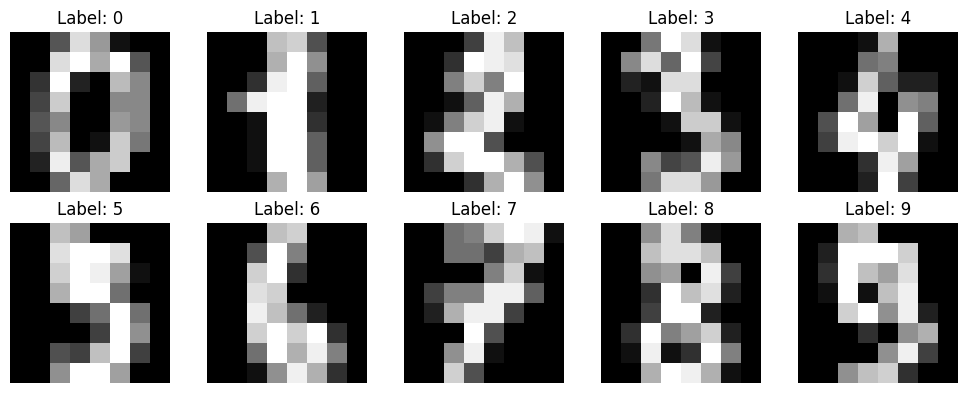

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Each image is an 8x8 grid of pixel brightness values (0 = black, 16 = white in this dataset). A Neural Network doesn't "see" a picture the way we do - it only sees 64 numbers per image.

In [3]:
pd.Series(y_labels).value_counts().sort_index()

0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

### Observation

The classes are reasonably balanced across all 10 digits - important, since a heavily imbalanced dataset (e.g. very few examples of the digit `8`) would make that class much harder to learn.

# Part 4 - Preparing the Image Data

## Normalizing Pixel Values

Raw pixel values here range from 0 to 16. Just like we scaled numeric features yesterday, we'll normalize pixels to a 0-1 range, which helps the network train faster and more stably.

In [4]:
X_normalized = X_images / 16.0

print("Before normalization - min:", X_images.min(), "max:", X_images.max())
print("After normalization  - min:", X_normalized.min(), "max:", X_normalized.max())

Before normalization - min: 0.0 max: 16.0
After normalization  - min: 0.0 max: 1.0


## Train / Test Split

Same idea as every previous lesson - we hold back data the model will never see during training.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

Training images: 1437
Testing images: 360


**Note:** unlike Day 1, we do **not** need `pd.get_dummies()` here - there are no categorical text columns. Pixel brightness values are already numeric.

# Part 5 - Build the Multi-Class ANN

Our images are already flattened into 64 numbers (a `Flatten` layer would be needed if we had the raw 8x8 grid, so we include it here anyway for clarity and so this same code works on raw MNIST images too).

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

model = Sequential([
    Input(shape=(8, 8)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

I0000 00:00:1787465671.717523     481 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787465671.719290     481 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787465687.342329     481 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787465694.655092     481 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787465694.656525     481 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1787465695.966833     481 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

### Reading This Architecture

- **`Input(shape=(8, 8))`** - each image arrives as an 8x8 grid.
- **`Flatten()`** - unrolls the 8x8 grid into a single list of 64 numbers, since `Dense` layers only accept 1-D input. (For full 28x28 MNIST images, this would flatten to 784 numbers instead.)
- **`Dense(64, activation="relu")`** and **`Dense(32, activation="relu")`** - two hidden layers, learning increasingly abstract patterns (edges → strokes → digit shapes).
- **`Dense(10, activation="softmax")`** - our multi-class output layer from Part 2, one neuron per digit.

Since we passed raw 8x8 images into `Input`, we need to reshape our flattened `X_train`/`X_test` back into 8x8 grids first.

In [7]:
X_train_grid = X_train.reshape(-1, 8, 8)
X_test_grid = X_test.reshape(-1, 8, 8)

print("Reshaped training data:", X_train_grid.shape)

Reshaped training data: (1437, 8, 8)


## Compile the Model

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

We use `sparse_categorical_crossentropy` (instead of yesterday's `binary_crossentropy`) because we now have 10 integer class labels (`0` to `9`) rather than a single 0/1 target. ("Sparse" simply means our labels are plain integers like `7`, rather than one-hot vectors like `[0,0,0,0,0,0,0,1,0,0]` - Keras handles the conversion internally.)

# Part 6 - Train the Model

In [9]:
history = model.fit(
    X_train_grid,
    y_train,
    epochs=40,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Training complete.")

Training complete.


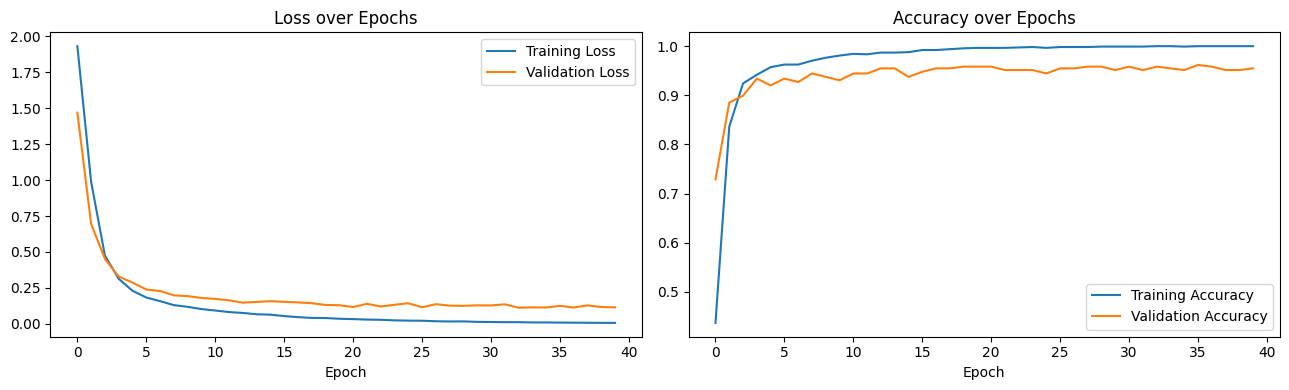

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# Part 7 - Evaluate on the Test Set

In [11]:
from sklearn.metrics import confusion_matrix, classification_report

test_loss, test_accuracy = model.evaluate(X_test_grid, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))

Test Loss: 0.0804
Test Accuracy: 0.975


In [12]:
probabilities = model.predict(X_test_grid, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predicted_classes,
    "Confidence": probabilities.max(axis=1).round(3)
})

comparison.head(10)

,Actual,Predicted,Confidence
0,5,5,0.998
1,2,2,1.000
2,8,8,0.923
3,1,1,0.797
4,7,7,0.999
5,2,2,0.967
6,6,6,1.000
7,2,2,1.000
8,6,6,1.000
9,5,5,1.000


### Why `np.argmax()`?

`model.predict()` returns 10 probabilities per image (one per digit). `np.argmax(probabilities, axis=1)` picks the **index** of the highest probability - which conveniently is also the predicted digit itself, since our classes are `0` through `9`.

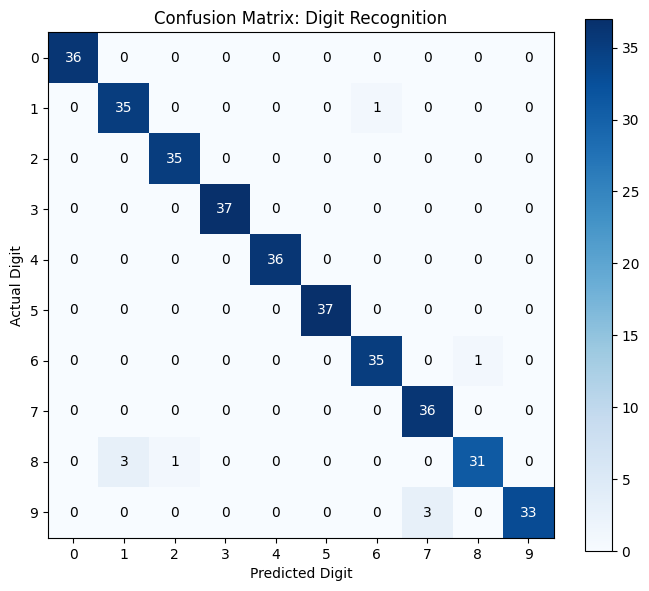

In [13]:
cm = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Confusion Matrix: Digit Recognition")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

### Reading a Multi-Class Confusion Matrix

Unlike Day 1's 2x2 matrix, this one is 10x10. The diagonal (top-left to bottom-right) shows correct predictions. Any value **off** the diagonal shows a specific confusion - for example, a value in row `4`, column `9` means some `4`s were mistakenly predicted as `9`s (a genuinely common human mistake too, since the shapes are similar!).

In [14]:
print(classification_report(y_test, predicted_classes))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      0.97      0.95        36
           2       0.97      1.00      0.99        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       0.97      0.97      0.97        36
           7       0.92      1.00      0.96        36
           8       0.97      0.89      0.93        35
           9       1.00      0.92      0.96        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



**Precision, recall, and F1-score are now reported per digit**, not just overall - useful for spotting which specific digits the model struggles with.

## Visualize Some Predictions

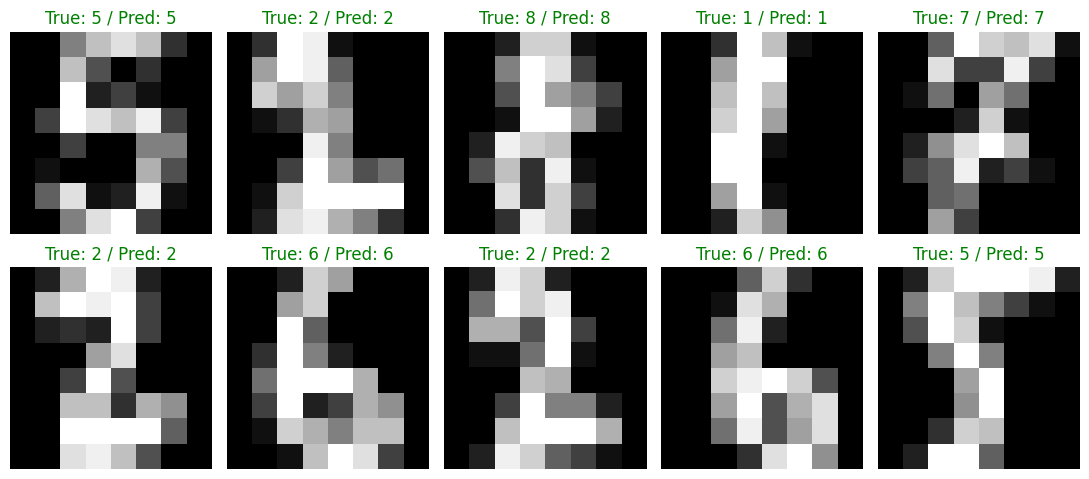

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for i, ax in enumerate(axes.flat):
    image = X_test_grid[i]
    true_label = y_test[i]
    pred_label = predicted_classes[i]

    ax.imshow(image, cmap="gray")
    color = "green" if true_label == pred_label else "red"
    ax.set_title(f"True: {true_label} / Pred: {pred_label}", color=color)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Part 8 - Does Adding More Hidden Layers Help?

The lesson plan's assignment for today asks: *"How does increasing hidden layers affect performance?"* Let's actually test it, instead of just guessing.

We'll train three versions of the same network - shallow, medium, and deep - and compare their test accuracy.

In [16]:
def build_and_train(hidden_layers, name):
    layers = [Input(shape=(8, 8)), Flatten()]
    for units in hidden_layers:
        layers.append(Dense(units, activation="relu"))
    layers.append(Dense(10, activation="softmax"))

    m = Sequential(layers)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X_train_grid, y_train, epochs=40, batch_size=16, verbose=0)

    loss, acc = m.evaluate(X_test_grid, y_test, verbose=0)
    print(f"{name:<25} hidden layers={hidden_layers} -> test accuracy = {acc:.4f}")
    return acc

results = {}
results["Shallow (1 layer)"] = build_and_train([32], "Shallow (1 layer)")
results["Medium (2 layers)"] = build_and_train([64, 32], "Medium (2 layers)")
results["Deep (4 layers)"] = build_and_train([128, 64, 32, 16], "Deep (4 layers)")

Shallow (1 layer)         hidden layers=[32] -> test accuracy = 0.9722


Medium (2 layers)         hidden layers=[64, 32] -> test accuracy = 0.9722


Deep (4 layers)           hidden layers=[128, 64, 32, 16] -> test accuracy = 0.9806


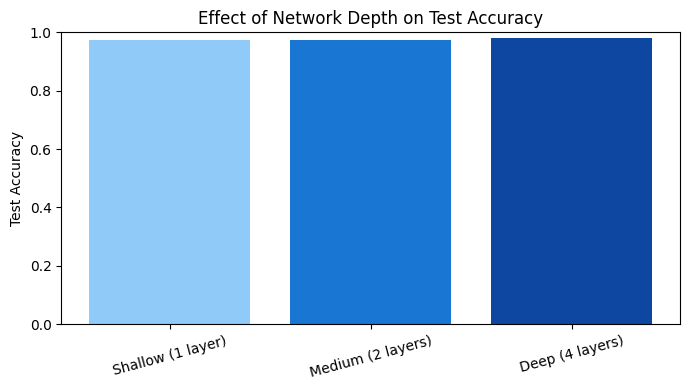

In [17]:
plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values(), color=["#90caf9", "#1976d2", "#0d47a1"])
plt.ylabel("Test Accuracy")
plt.title("Effect of Network Depth on Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Interpreting the Result

In this run, all three networks performed well (this dataset is fairly easy), and the **deep network (4 layers) actually edged out the shallow and medium ones slightly** (about 98.1% vs 97.2%). That will not always be the case - on a smaller or noisier dataset, a deep network is more likely to overfit and *underperform* a shallower one, because it has more parameters to fit with the same limited data.

**The general rule:** more layers = more capacity to learn complex patterns, but also more risk of overfitting and slower training, especially with small datasets. Network depth should match the complexity of the problem and the amount of available data - it is worth testing a few sizes empirically, exactly as we just did, rather than assuming bigger is always better.


# Part 9 - Reducing Overfitting with Dropout

`Dropout` is a technique that randomly "switches off" a fraction of neurons during each training step, forcing the network to not rely too heavily on any single neuron.

In [18]:
from tensorflow.keras.layers import Dropout

model_with_dropout = Sequential([
    Input(shape=(8, 8)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_with_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_dropout = model_with_dropout.fit(
    X_train_grid, y_train,
    epochs=40, batch_size=16,
    validation_split=0.2, verbose=0
)

test_loss_d, test_acc_d = model_with_dropout.evaluate(X_test_grid, y_test, verbose=0)
print("Test Accuracy with Dropout:", round(test_acc_d, 4))

Test Accuracy with Dropout: 0.975


### What Does `Dropout(0.3)` Mean?

During training, **30%** of the neurons in that layer are randomly ignored on each batch. This prevents the network from becoming overly dependent on a few specific neurons, similar in spirit to how pruning a Decision Tree (Week 5 Day 2) prevents it from memorising noise. Dropout is only active during training - at prediction time, all neurons are used.

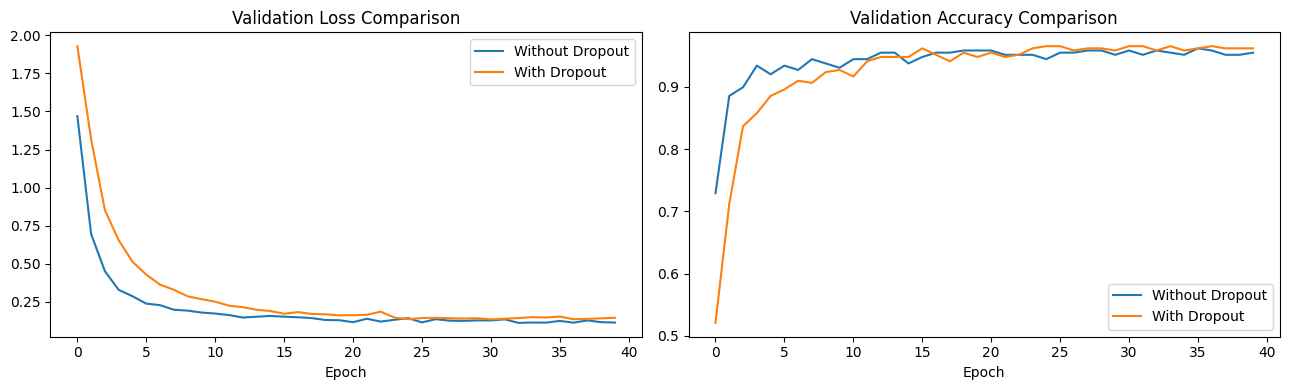

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["val_loss"], label="Without Dropout")
axes[0].plot(history_dropout.history["val_loss"], label="With Dropout")
axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["val_accuracy"], label="Without Dropout")
axes[1].plot(history_dropout.history["val_accuracy"], label="With Dropout")
axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### Key Takeaways from Parts 8-9

1. More hidden layers ≠ automatically better performance, especially on smaller datasets.
2. Dropout is a simple, effective way to reduce overfitting by preventing over-reliance on specific neurons.
3. Both are examples of a bigger theme from this entire course: **model complexity must match the size and complexity of your data** - the same lesson we learned with Decision Tree depth in Week 5.

# Mini Practical Activity

1. Pick 5 misclassified test images (`Actual != Predicted`) and display them with `imshow`, like we did earlier.
2. For each one, guess *why* the model might have confused it (e.g. does it look like it could genuinely be the predicted digit?).
3. Try changing the `Dropout` rate from `0.3` to `0.5` - does test accuracy improve or get worse?

### Exercise 1

Replace `softmax` with `sigmoid` in the output layer (keeping 10 neurons) and try training again. What happens to the reported accuracy, and why is `softmax` the correct choice here?

### Exercise 2

Increase `batch_size` from `16` to `64`. Does training take a different number of "steps" to complete each epoch? Does final accuracy change?

### Exercise 3

Using the `results` dictionary from Part 8, write one sentence explaining which network size you'd actually recommend for this dataset, and why.

# Lesson Summary

Today, you learned how to:

- Explain forward pass, loss, backpropagation, and epochs as the four repeating stages of training.
- Distinguish binary classification (`sigmoid`) from multi-class classification (`softmax`).
- Load and visualize an image dataset for classification.
- Normalize pixel data and reshape it for a `Flatten` + `Dense` ANN.
- Train a multi-class ANN using `sparse_categorical_crossentropy`.
- Read a 10x10 confusion matrix and a per-class classification report.
- Compare shallow, medium, and deep networks empirically instead of guessing.
- Use `Dropout` to reduce overfitting.

# Functions and Concepts Learned Today

| Item | Purpose |
|---|---|
| Forward Pass | Data flows through the network to produce a prediction |
| Backpropagation | Calculates how much each weight contributed to the error |
| Epoch | One complete pass of the training data through forward pass + backprop |
| Softmax | Multi-class output activation; converts scores into probabilities summing to 1 |
| `sparse_categorical_crossentropy` | Loss function for multi-class problems with integer labels |
| `load_digits()` | Built-in scikit-learn dataset of handwritten digit images |
| `Flatten()` | Converts a 2-D image grid into a 1-D list for `Dense` layers |
| `np.argmax()` | Finds the index (class) with the highest predicted probability |
| Confusion Matrix (multi-class) | Extends the binary 2x2 matrix to an NxN grid, one row/column per class |
| `Dropout(rate)` | Randomly disables a fraction of neurons during training to reduce overfitting |
| Network depth experiment | Comparing shallow vs. medium vs. deep networks empirically |

# Key Takeaways

✅ Training is always: forward pass → loss → backpropagation → weight update, repeated every batch, every epoch.

✅ `softmax` + `sparse_categorical_crossentropy` is the standard multi-class equivalent of yesterday's `sigmoid` + `binary_crossentropy`.

✅ Image data must be flattened before it can enter a `Dense` layer.

✅ A multi-class confusion matrix reveals exactly *which* classes get confused with each other, not just an overall error rate.

✅ Adding more hidden layers doesn't automatically improve performance - it must be tested, not assumed.

✅ Dropout is a simple, powerful tool against overfitting, conceptually similar to pruning a Decision Tree.

# Assignment

Submit a Jupyter Notebook with:

1. An ANN implementation on the digits dataset (or full MNIST, if you have internet access).
2. A plotted training accuracy/loss curve.
3. Your final test accuracy.
4. A short written explanation, backed by your own results from Part 8, answering: **"How does increasing hidden layers affect performance?"**
5. At least one experiment with `Dropout`, and a sentence on whether it helped.

# Final Reflection

1. In your own words, what happens during backpropagation?
2. Why do we need `softmax` instead of `sigmoid` for a 10-class problem?
3. Why must an image be flattened before entering a `Dense` layer?
4. What does a value off the diagonal of a confusion matrix tell you?
5. Based on your Part 8 results, did more hidden layers help or hurt accuracy on this dataset? Why do you think that happened?
6. What does `Dropout(0.3)` actually do during training?
7. Why is `Dropout` not applied when the model is making real predictions?
8. How is today's multi-class problem similar to, and different from, yesterday's binary loan-approval problem?

# Preview: Week 7 - Deep Learning & CNNs

Next week, we introduce **Convolutional Neural Networks (CNNs)** - a specialised architecture for image data that doesn't require flattening images into a flat list of pixels.

Instead, CNNs use **filters** that slide across the image, directly detecting edges, shapes, and textures while preserving the image's spatial structure - something today's plain ANN completely throws away in the `Flatten()` step. We'll revisit this exact digit dataset (and possibly the full MNIST set) to see how much a CNN improves on today's results.